In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



In [4]:
# Load Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

Target Classes:
['malignant' 'benign']


target
1    357
0    212
Name: count, dtype: int64


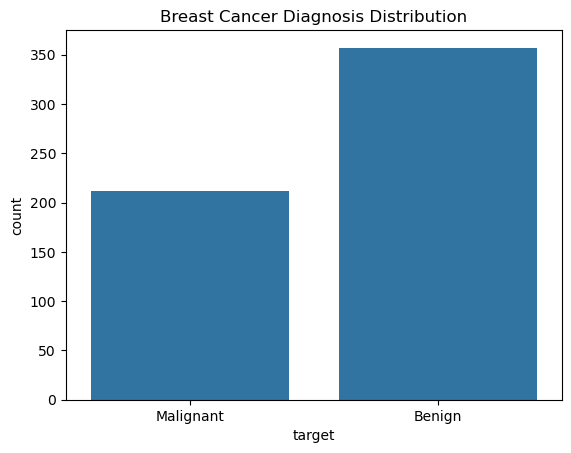

In [5]:
print(y.value_counts())

sns.countplot(x=y)
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Breast Cancer Diagnosis Distribution")
plt.show()

In [6]:
#Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
#Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
#Train Logistic Regression
model = LogisticRegression(max_iter=2000)

model.fit(X_train_scaled, y_train)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

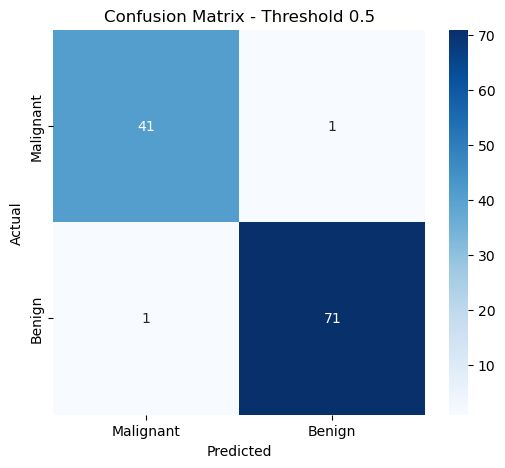

In [9]:
#Confusion Matrix
threshold = 0.5

y_pred = (y_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Threshold 0.5")
plt.show()

In [11]:
# Threshold tuning

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

results = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

   Threshold  Accuracy  Precision  Recall  F1 Score
0        0.2     0.982      0.973   1.000     0.986
1        0.3     0.982      0.973   1.000     0.986
2        0.4     0.982      0.986   0.986     0.986
3        0.5     0.982      0.986   0.986     0.986
4        0.6     0.956      0.986   0.944     0.965
5        0.7     0.947      0.985   0.931     0.957
6        0.8     0.939      0.985   0.917     0.950


In [12]:
# Find the best threshold
best = results_df.loc[results_df["F1 Score"].idxmax()]

print("Best Threshold:", best["Threshold"])
print("Accuracy:", round(best["Accuracy"], 3))
print("Precision:", round(best["Precision"], 3))
print("Recall:", round(best["Recall"], 3))
print("F1 Score:", round(best["F1 Score"], 3))

Best Threshold: 0.2
Accuracy: 0.982
Precision: 0.973
Recall: 1.0
F1 Score: 0.986


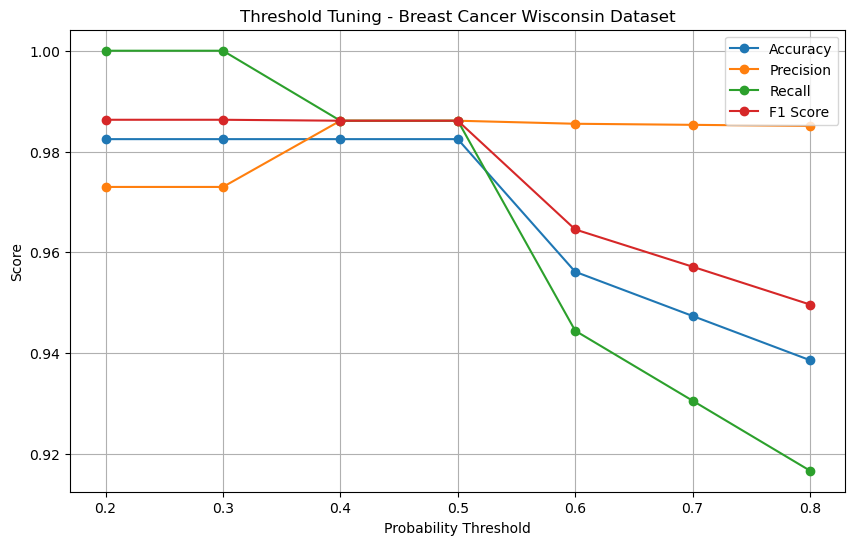

In [13]:
# Plot threshold performance

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Threshold"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["Threshold"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Threshold"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Threshold"],
    results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning - Breast Cancer Wisconsin Dataset")
plt.legend()
plt.grid(True)
plt.show()